# Can a neural network save us from trying 120 circuit recipes?

**A short walkthrough of our logic-synthesis project.**

A circuit computes a function using logic gates. Different gate arrangements can produce the same answers with different **area** (chip space) and **delay** (time to produce an output).

A **recipe** is an ordered sequence of optimization commands. We ask whether an NN can recommend a useful recipe for a circuit it has never seen.

```text
205 existing circuits + 120 recipes
              |
      Measure every combination once
              |
      Train on some circuits
              |
      Recommend recipes for unseen circuits
              |
      Compare quality and synthesis time
```

Read from top to bottom, or choose **Restart Kernel and Run All**. The saved outputs are included. This notebook uses the measured dataset; it does not rebuild ABC or repeat the expensive synthesis sweep.

## 1. Load the experiment

We use pandas for the tables, PyTorch for the NN, and Matplotlib for two result plots. The notebook finds the project folder automatically.

In [1]:
from pathlib import Path
from io import BytesIO
import json

import numpy as np
import pandas as pd
import torch
from torch import nn
from sklearn.preprocessing import StandardScaler
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data/processed/dataset.csv").exists())
torch.set_num_threads(1)
pd.set_option("display.max_colwidth", 65)
pd.set_option("display.max_columns", 12)
pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams.update({"figure.figsize": (8, 4), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})

def show(fig):
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=130, bbox_inches="tight")
    display(Image(data=buffer.getvalue()))
    plt.close(fig)

print("Ready: pandas tables, a CPU neural network, and plots.")

Ready: pandas tables, a CPU neural network, and plots.


### What does one dataset row mean?

**One row = one circuit optimized using one recipe.**

- `circuit`, `family`: the circuit and its source collection.
- `recipe_ops`: optimization operations, applied in order.
- `base_area`, `base_delay`: measurements before applying a recipe.
- `area`, `delay`: measurements after applying that recipe.
- `runtime_s`: recorded time for that complete recipe run.

Area is measured in square micrometres; delay is measured in picoseconds.

In [2]:
data = pd.read_csv(ROOT / "data/processed/dataset.csv")
print(f"Measured experiments: {len(data):,}")
print(f"Independent circuits: {data.circuit.nunique()}")
print(f"Candidate recipes per circuit: {data.recipe_id.nunique()}")
print(f"Successful measurements: {data.status.eq('ok').sum():,}")

columns = ["circuit", "family", "recipe_id", "recipe_ops", "base_area",
           "base_delay", "area", "delay", "runtime_s"]
display(data[columns].head())

Measured experiments: 24,600
Independent circuits: 205
Candidate recipes per circuit: 120
Successful measurements: 24,600


,circuit,family,recipe_id,recipe_ops,base_area,base_delay,area,delay,runtime_s
0,adder,EPFL-arith,R000,b rw rwz b rwz b,865.830,4065.130,882.060,3790.950,0.206
1,adder,EPFL-arith,R001,b rw rf b rw rwz b rfz rwz b,865.830,4065.130,882.320,4081.940,0.235
2,adder,EPFL-arith,R002,b rf rw rsz rw rfz rsz rwz,865.830,4065.130,964.520,4060.250,0.233
3,adder,EPFL-arith,R003,rf rw rw rf rsz rw,865.830,4065.130,718.200,4067.680,0.205
4,adder,EPFL-arith,R004,rfz rfz rw rfz rw rwz rfz,865.830,4065.130,884.720,4074.080,0.194


### Where did the circuits and recipes come from?

These are existing public circuit designs: EPFL arithmetic/control circuits, ISCAS-85 test circuits, and MCNC logic-synthesis benchmarks. We selected **205 combinational circuits**, whose outputs depend on their current inputs rather than stored state.

Our **120 recipes** contain 6–12 optimization operations. They include established scripts and sampled sequences. `resyn2` is an established ten-operation sequence, stored as `R001`.

In [3]:
circuits = data.drop_duplicates("circuit")
recipes = data[["recipe_id", "recipe_ops"]].drop_duplicates().sort_values("recipe_id")

print("Circuits from each benchmark family:")
display(circuits.groupby("family").size().rename("circuits").to_frame())
print("First five recipes (each is an ordered list of operations):")
display(recipes.head())

Circuits from each benchmark family:
First five recipes (each is an ordered list of operations):


,circuits
family,
EPFL-arith,7
EPFL-ctrl,9
ISCAS85,10
MCNC,179


,recipe_id,recipe_ops
0,R000,b rw rwz b rwz b
1,R001,b rw rf b rw rwz b rfz rwz b
2,R002,b rf rw rsz rw rfz rsz rwz
3,R003,rf rw rw rf rsz rw
4,R004,rfz rfz rw rfz rw rwz rfz


## 2. Turn area and delay into one score

Circuits differ greatly in size. We divide each outcome by the same circuit's original measurements:

$$y_A = \frac{A}{A_0},\qquad y_D = \frac{D}{D_0},\qquad J = \frac{y_A+y_D}{2}.$$

**Lower $J$ is better.** A value of 0.90 is a 10% reduction in the equally weighted normalized objective. Area and delay can trade off, so the two individual changes can differ.

In [4]:
data["yA"] = data.area / data.base_area
data["yD"] = data.delay / data.base_delay
data["J"] = (data.yA + data.yD) / 2

print("Example: two measured recipes on the same circuit, c1908.")
example = data[data.circuit.eq("c1908") & data.recipe_id.isin(["R001", "R037"])]
display(example[["circuit", "recipe_id", "area", "delay", "yA", "yD", "J"]])

Example: two measured recipes on the same circuit, c1908.


,circuit,recipe_id,area,delay,yA,yD,J
2041,c1908,R001,385.970,621.870,1.083,0.929,1.006
2077,c1908,R037,343.940,602.630,0.965,0.900,0.932


## 3. Exhaustive search gives us the reference answer

**ABC** is the synthesis software that applies a recipe and measures the resulting circuit. Internally it transforms an **AIG**: a graph of AND operations and optional inversions. It then maps that graph to gates from the NanGate45 cell library.

The expensive dataset-building loop was essentially this (**shown for explanation; it is not rerun here**):

```python
from circuit_recipe.synthesis import ABC

abc = ABC()
inventory = pd.read_csv(ROOT / "data/processed/circuits.csv")
rows = []
for circuit in inventory.itertuples():
    path = ROOT / circuit.path
    baseline = abc.measure(path)
    for recipe in recipes.itertuples():
        result = abc.measure(path, recipe.recipe_ops)
        rows.append({
            "circuit": circuit.circuit,
            "recipe_id": recipe.recipe_id,
            "J": 0.5 * (result["area"] / baseline["area"]
                      + result["delay"] / baseline["delay"]),
        })
```

Every recipe restarts from the original circuit. We measured **205 × 120 = 24,600 outcomes**. For each circuit, the lowest measured score is the **exhaustive-search oracle**: the best result within this finite recipe library.

We can now inspect those saved measurements without paying the synthesis cost again. Reading this table is not a timing measurement of exhaustive synthesis.

In [5]:
# Rows are circuits; columns are recipes; each entry is a measured score.
J = data.pivot(index="circuit", columns="recipe_id", values="J").sort_index()
print(f"Outcome table: {J.shape[0]} circuits × {J.shape[1]} recipes")
display(J.iloc[:5, :6])

oracle = pd.DataFrame({"best_recipe": J.idxmin(axis=1), "best_J": J.min(axis=1)})
print("Exhaustive-search answer for the first five circuits:")
display(oracle.head())

Outcome table: 205 circuits × 120 recipes
Exhaustive-search answer for the first five circuits:


recipe_id,R000,R001,R002,R003,R004,R005
circuit,,,,,,
5xp1,0.891,0.962,0.860,0.960,0.879,1.012
9sym,0.978,0.968,1.007,0.973,0.971,0.996
9symml,1.003,1.025,1.007,1.004,1.029,1.005
Z5xp1,0.855,0.778,0.767,0.692,0.649,0.855
Z9sym,1.010,0.971,0.970,0.997,1.023,1.072


,best_recipe,best_J
circuit,,
5xp1,R067,0.805
9sym,R039,0.948
9symml,R023,0.936
Z5xp1,R066,0.641
Z9sym,R054,0.939


## 4. Describe the circuit before choosing a recipe

The NN gets **50 features**, all available before executing its recommended recipes:

| Features | Count | Simple meaning |
|---|---:|---|
| Graph statistics (`c_...`) | 24 | Size, depth, branching, sharing, and local logic patterns. |
| Baseline mapping | 4 | Original mapped area/delay and size-normalized versions. |
| Diagnostic probes (`p_...`) | 22 | Node/depth changes after eleven short transformations. |

Each probe starts from the original graph and stops before mapping. Collecting these features takes time, which is included in our NN runtime comparison.

We compress ten size-related features using `log(1 + x)`. Circuit names, families, actual recipe outcomes, and runtimes are not NN inputs.

In [6]:
one_per_circuit = circuits.set_index("circuit").sort_index()
feature_columns = [c for c in data if c.startswith(("c_", "p_"))]
X = one_per_circuit[feature_columns].astype(float).copy()

log_columns = ["c_n_pi", "c_n_po", "c_n_and", "c_depth", "c_n_edges",
               "c_and_per_depth", "c_fo_max", "c_width_max",
               "c_width_mean", "c_lvl_gap_max"]
X[log_columns] = np.log1p(X[log_columns])
X["m_log_area"] = np.log(one_per_circuit.base_area)
X["m_log_delay"] = np.log(one_per_circuit.base_delay)
X["m_area_per_node"] = one_per_circuit.base_area / one_per_circuit.c_n_and
X["m_delay_per_level"] = one_per_circuit.base_delay / one_per_circuit.c_depth
X = X.astype("float32")

print(f"NN input table: {X.shape[0]} circuits × {X.shape[1]} features")
print("A small view of the input features:")
display(X[["c_n_and", "c_depth", "p_b_nodes", "p_b_depth",
           "m_log_area", "m_log_delay"]].head())

NN input table: 205 circuits × 50 features
A small view of the input features:


,c_n_and,c_depth,p_b_nodes,p_b_depth,m_log_area,m_log_delay
circuit,,,,,,
5xp1,4.883,2.398,0.947,1.000,4.389,4.957
9sym,5.476,2.708,0.958,0.929,5.009,5.488
9symml,5.357,2.639,0.948,0.923,4.876,5.421
Z5xp1,5.318,2.398,0.921,0.800,4.845,5.291
Z9sym,5.226,2.398,0.919,1.000,4.787,5.284


## 5. Keep entire test circuits out of training

Splitting individual rows would let measurements of the same circuit appear on both sides. We split **by circuit**, keeping all 120 outcomes together.

For this live demonstration, we reuse the paper's first outer fold. Its epoch setting was selected using inner validation on its training circuits only.

```text
205 circuits
  ├── 164 training circuits → fit preprocessing and train the NN
  └──  41 test circuits     → predict first, then inspect selected outcomes
```

The paper repeats five folds three times. We will show those saved full-study results after the single-fold demonstration.

In [7]:
split = json.loads((ROOT / "results/neural/r0_f0_split.json").read_text())
train_ids, test_ids = split["train"], split["test"]
X_train, X_test = X.loc[train_ids], X.loc[test_ids]
Y_train, Y_test = J.loc[train_ids], J.loc[test_ids]
assert set(train_ids).isdisjoint(test_ids)

print(f"Training: {len(train_ids)} circuits, {Y_train.size:,} measured outcomes")
print(f"Testing:  {len(test_ids)} circuits, {Y_test.size:,} hidden outcomes")
print("Circuit overlap:", len(set(train_ids) & set(test_ids)))

Training: 164 circuits, 19,680 measured outcomes
Testing:  41 circuits, 4,920 hidden outcomes
Circuit overlap: 0


## 6. Prepare the training targets

We want the NN to learn which recipes are relatively good for each circuit.

1. Subtract each training circuit's average recipe score (this preserves the ranking).
2. Compute each recipe's mean centered training score, $\mu_R$.
3. Train the NN to predict the remaining adjustment, scaled by its standard deviation $s$.

$$\text{training target} = \frac{\widetilde J(C,R)-\mu_R}{s}, \qquad
\widetilde J(C,R)=J(C,R)-\operatorname{mean}_{R'}J(C,R').$$

Input scaling and all target statistics come from **training circuits only**.

In [8]:
scaler = StandardScaler().fit(X_train)
x_train = torch.tensor(scaler.transform(X_train), dtype=torch.float32)
x_test = torch.tensor(scaler.transform(X_test), dtype=torch.float32)

centered = Y_train.to_numpy() - Y_train.to_numpy().mean(axis=1, keepdims=True)
recipe_mean = centered.mean(axis=0).astype("float32")
residual = centered - recipe_mean
residual_scale = max(float(residual.std()), 1e-6)
y_train = torch.tensor(residual / residual_scale, dtype=torch.float32)

print("Input tensor:", tuple(x_train.shape))
print("Target tensor:", tuple(y_train.shape))
print("One training circuit has 50 inputs and 120 target scores.")

Input tensor: (164, 50)
Target tensor: (164, 120)
One training circuit has 50 inputs and 120 target scores.


## 7. Build and train the small neural network

```text
50 circuit features → 64 hidden units → 32 hidden units → 120 recipe scores
```

This is a regression network: lower output scores mean better predicted recipes. ReLU supplies nonlinearity; dropout regularizes training.

The last layer starts at zero, so the initial recipe ranking is the training-set mean ranking. The network learns how to adjust it for a particular circuit.

In [9]:
torch.manual_seed(0)
model = nn.Sequential(
    nn.Linear(50, 64), nn.ReLU(), nn.Dropout(0.1),
    nn.Linear(64, 32), nn.ReLU(), nn.Dropout(0.1),
    nn.Linear(32, 120),
)
nn.init.zeros_(model[-1].weight)
nn.init.zeros_(model[-1].bias)

print(model)
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters()):,}")

Sequential(
  (0): Linear(in_features=50, out_features=64, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.1, inplace=False)
  (3): Linear(in_features=64, out_features=32, bias=True)
  (4): ReLU()
  (5): Dropout(p=0.1, inplace=False)
  (6): Linear(in_features=32, out_features=120, bias=True)
)
Trainable parameters: 9,304


We minimize **mean squared error** between predicted and measured training adjustments. AdamW updates the weights. An epoch is one pass through the training circuits.

We reuse the epoch count chosen inside this fold's training partition. The 41 test circuits do not choose the epoch count.

In [10]:
tuning = json.loads((ROOT / "results/neural/r0_f0_nn_full_tuning.json").read_text())
params = tuning["chosen"]["params"]
optimizer = torch.optim.AdamW(model.parameters(), lr=params["lr"],
                             weight_decay=params["weight_decay"])
losses = []
model.train()
for epoch in range(params["epochs"]):
    optimizer.zero_grad(set_to_none=True)
    loss = nn.functional.mse_loss(model(x_train), y_train)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

print(f"Epochs selected by inner validation: {params['epochs']}")
print(f"Training MSE: {losses[0]:.4f} → {losses[-1]:.4f}")

Epochs selected by inner validation: 25
Training MSE: 1.0000 → 0.8740


## 8. Recommend recipes for unseen circuits

At inference, restore the training mean and scale:

$$\widehat{\widetilde J}(C,R)=\mu_R+s\,f_\theta(x_C)_R.$$

One forward pass gives all 120 recipe scores. Sorting these scores does not execute any recipes. We can execute the best predicted recipe, or execute the top five and keep their best measured result.

In [11]:
model.eval()  # Disable dropout for prediction.
with torch.inference_mode():
    predicted = recipe_mean + residual_scale * model(x_test).numpy()

scores = pd.DataFrame(predicted, index=test_ids, columns=J.columns)
ranked_recipes = scores.apply(lambda row: row.sort_values(kind="stable").index.tolist(), axis=1)

print(f"Predicted scores: {scores.shape[0]} unseen circuits × {scores.shape[1]} recipes")
display(scores.iloc[:5, :6])
print("First unseen circuit:", test_ids[0])
print("NN's first five recommendations:", ranked_recipes.iloc[0][:5])

Predicted scores: 41 unseen circuits × 120 recipes
First unseen circuit: 9sym
NN's first five recommendations: ['R033', 'R002', 'R065', 'R082', 'R093']


recipe_id,R000,R001,R002,R003,R004,R005
9sym,-0.002,-0.014,-0.025,0.008,0.009,0.008
amd,0.045,-0.020,-0.022,0.006,-0.015,0.008
apex3,0.019,-0.012,-0.022,0.003,-0.001,0.010
apex4,0.016,-0.013,-0.022,0.007,0.000,0.008
b3,0.038,-0.019,-0.020,0.022,-0.003,0.017


### Evaluate the recommendations

The recommendation is already fixed. Now we reveal the measured scores of the chosen recipes.

- **Best fixed recipe:** the recipe with the lowest mean training objective; one run per test circuit.
- **NN top one:** execute one recommended recipe.
- **NN top five:** execute five recommendations and keep their best result.
- **Global top five:** execute the same five training-ranked recipes for every circuit; a simple shortlist baseline.
- **Oracle:** execute all 120 recipes and keep their best result.

$$\mathrm{Gain}=100\frac{J_{fixed}-J_{selected}}{J_{fixed}},\qquad
\mathrm{Gap}=100\frac{J_{selected}-J_{oracle}}{J_{oracle}}.$$

Higher gain and lower gap are better. This cell demonstrates **one fold**, so its averages can differ from the paper's full-study averages.

In [12]:
global_order = Y_train.mean().sort_values(kind="stable").index.tolist()
fixed_J = Y_test[global_order[0]]
oracle_J = Y_test.min(axis=1)  # Exhaustive search inspects every candidate.

choices = pd.DataFrame(index=test_ids)
choices["Best fixed"] = fixed_J
for k in [1, 5]:
    choices[f"NN top {k}"] = [Y_test.loc[c, ranked_recipes[c][:k]].min() for c in test_ids]
choices["Global top 5"] = Y_test[global_order[:5]].min(axis=1)
choices["Exhaustive oracle"] = oracle_J

fold_results = pd.DataFrame({
    "Recipe runs": [1, 1, 5, 5, 120],
    "Mean objective": choices.mean(),
    "Mean gain vs fixed (%)": choices.apply(lambda col: 100 * ((fixed_J - col) / fixed_J).mean()),
    "Mean gap to oracle (%)": choices.apply(lambda col: 100 * ((col - oracle_J) / oracle_J).mean()),
})
print(f"Demonstration results: {len(test_ids)} circuits held out from training")
display(fold_results.round(3))

Demonstration results: 41 circuits held out from training


,Recipe runs,Mean objective,Mean gain vs fixed (%),Mean gap to oracle (%)
Best fixed,1,0.840,0.000,10.210
NN top 1,1,0.845,-0.553,10.483
NN top 5,5,0.793,5.634,3.441
Global top 5,5,0.794,5.415,3.774
Exhaustive oracle,120,0.766,8.706,0.000


### Inspect one recommendation

This is the first test circuit in the saved split, chosen by its position in the split rather than its outcome. The NN used only its 50 input features. The measured outcomes below become available after executing its shortlist.

In [13]:
circuit = test_ids[0]
shortlist = ranked_recipes[circuit][:5]
recipe_lookup = recipes.set_index("recipe_id")
preview = recipe_lookup.loc[shortlist].copy()
preview.insert(0, "NN rank", range(1, 6))
preview["Predicted relative score"] = scores.loc[circuit, shortlist]
preview["Measured J"] = Y_test.loc[circuit, shortlist]

print("Unseen circuit:", circuit)
print("Exhaustive-search best recipe:", Y_test.loc[circuit].idxmin())
print(f"Exhaustive-search best J: {oracle_J[circuit]:.4f}")
display(preview)

Unseen circuit: 9sym
Exhaustive-search best recipe: R039
Exhaustive-search best J: 0.9478


,NN rank,recipe_ops,Predicted relative score,Measured J
recipe_id,,,,
R033,1,rfz rwz rw rw rw rwz rwz b rw rs rs,-0.028,1.007
R002,2,b rf rw rsz rw rfz rsz rwz,-0.025,1.007
R065,3,b rw rw rwz rs rsz rfz rsz rwz rwz,-0.024,1.031
R082,4,rf b rwz rw b rwz rsz rs b rw,-0.022,0.986
R093,5,rf b rwz rs rsz b rw,-0.021,1.005


## 9. What happened across the full study?

The paper uses **five folds repeated three times**: 15 outer evaluations. Every circuit is tested three times, each by a model that did not train on it. The following table uses those saved predictions; it does not reuse our live demonstration as the full result.

For the **95% confidence interval**, average the three gains for each circuit, resample the 205 circuit averages with replacement 2,000 times, and take the 2.5th and 97.5th percentiles of the resampled means. This describes uncertainty in the average gain across circuits.

In [14]:
saved = pd.read_csv(ROOT / "results/neural/selections.csv")
saved = saved[saved.model.eq("nn_full")]

def confidence_interval(values):
    values = np.asarray(values)
    rng = np.random.default_rng(2026)
    means = values[rng.integers(0, len(values), size=(2000, len(values)))].mean(axis=1)
    return np.quantile(means, [0.025, 0.975])

rows = []
for label, selector, k in [("Best fixed", "global", 1), ("NN top 1", "learned", 1),
                           ("NN top 5", "learned", 5), ("Global top 5", "global", 5)]:
    subset = saved[saved.selector.eq(selector) & saved.k.eq(k)]
    per_circuit = subset.groupby("circuit")[["improvement", "regret"]].mean()
    lo, hi = confidence_interval(per_circuit.improvement)
    rows.append({"Method": label, "Mean gain vs fixed (%)": per_circuit.improvement.mean(),
                 "95% interval for gain": f"[{lo:.2f}, {hi:.2f}]",
                 "Mean gap to oracle (%)": per_circuit.regret.mean()})
full_results = pd.DataFrame(rows).set_index("Method")
print("Full-study quality: 205 circuits, each tested in three repeats")
display(full_results.round(3))
print("The NN top-one interval includes zero: its mean improvement remains uncertain.")

Full-study quality: 205 circuits, each tested in three repeats
The NN top-one interval includes zero: its mean improvement remains uncertain.


,Mean gain vs fixed (%),95% interval for gain,Mean gap to oracle (%)
Method,,,
Best fixed,0.000,"[0.00, 0.00]",9.973
NN top 1,0.191,"[-0.40, 0.79]",9.597
NN top 5,5.119,"[4.54, 5.70]",3.986
Global top 5,5.014,"[4.50, 5.55]",4.130


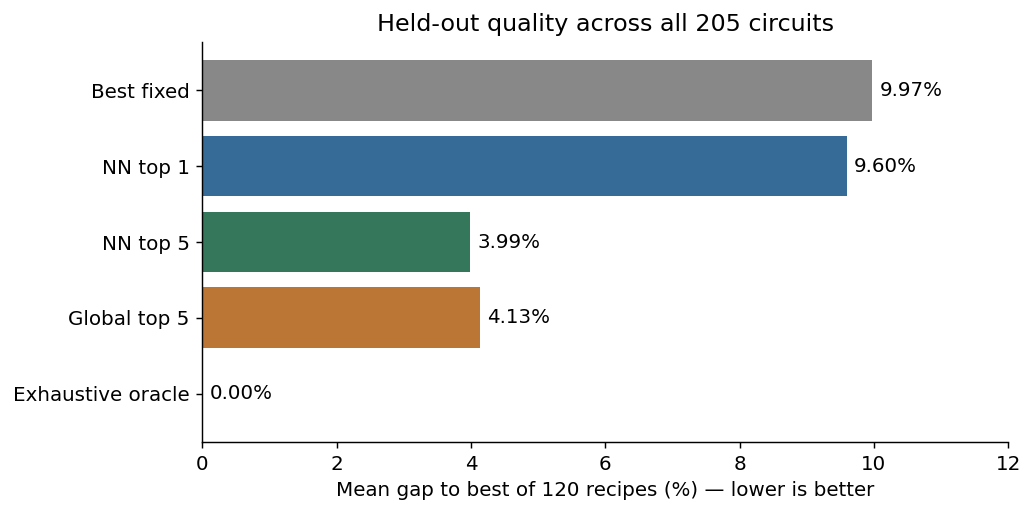

In [15]:
quality = full_results["Mean gap to oracle (%)"].copy()
quality.loc["Exhaustive oracle"] = 0
fig, ax = plt.subplots()
bars = ax.barh(quality.index, quality.values,
               color=["#888888", "#356b96", "#34775b", "#bb7534", "#444444"])
ax.bar_label(bars, fmt="%.2f%%", padding=4)
ax.set(xlabel="Mean gap to best of 120 recipes (%) — lower is better",
       title="Held-out quality across all 205 circuits", xlim=(0, 12))
ax.invert_yaxis()
show(fig)

## 10. How much synthesis time did we save?

We reran all 120 recipes on **12 circuits**, selected across the four families and their size quartiles. Each timing circuit was unseen by its NN. Timing includes **feature collection, prediction, and all executed recipe runs**, with the predictor already loaded.

$$\mathrm{Speedup}=\frac{\text{mean exhaustive time}}{\text{mean selector time}}.$$

The 12-circuit timing audit is separate from the 205-circuit quality evaluation above. These are recorded synthesis timings; the time spent reading the saved CSV in this notebook is not a synthesis benchmark.

In [16]:
timing = pd.read_csv(ROOT / "results/neural_runtime/summary.csv")
rows = []
for label, name, k in [("Best fixed", "global", 1), ("NN top 1", "nn_full", 1),
                       ("NN top 5", "nn_full", 5), ("Global top 5", "global", 5),
                       ("Exhaustive oracle", "exhaustive", 120)]:
    row = timing[timing.model.eq(name) & timing.k.eq(k)].iloc[0]
    rows.append({"Method": label, "Recipe runs": k, "Mean time (s)": row.cost_s,
                 "Speedup vs exhaustive": row.ratio_of_mean_times,
                 "Time saved (%)": row.time_saved_pct})
runtime_results = pd.DataFrame(rows).set_index("Method")
print("Separate serial timing audit: 12 circuits; model already loaded")
display(runtime_results.round(2))

Separate serial timing audit: 12 circuits; model already loaded


,Recipe runs,Mean time (s),Speedup vs exhaustive,Time saved (%)
Method,,,,
Best fixed,1,0.410,110.410,99.090
NN top 1,1,1.390,32.180,96.890
NN top 5,5,2.920,15.370,93.490
Global top 5,5,2.220,20.180,95.050
Exhaustive oracle,120,44.840,1.000,0.000


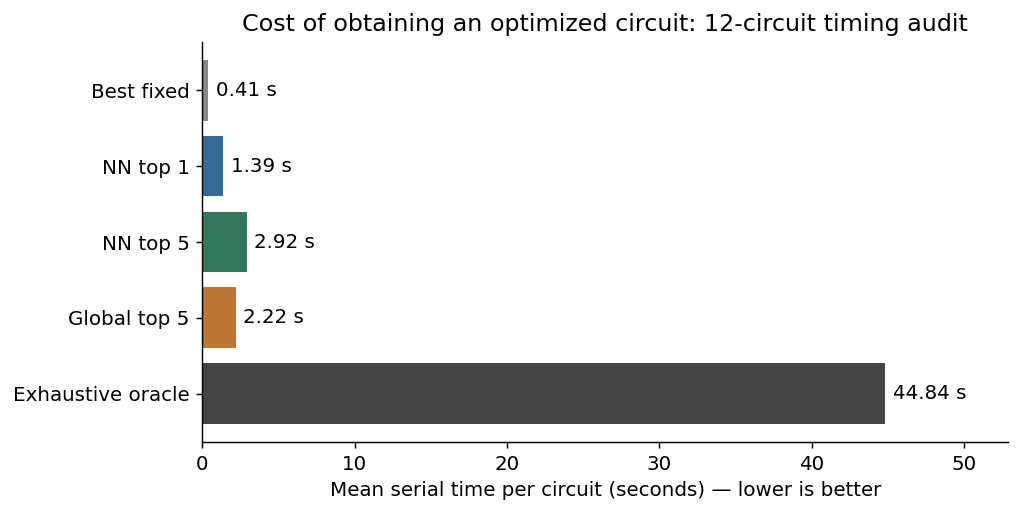

In [17]:
seconds = runtime_results["Mean time (s)"]
fig, ax = plt.subplots()
bars = ax.barh(seconds.index, seconds.values,
               color=["#888888", "#356b96", "#34775b", "#bb7534", "#444444"])
ax.bar_label(bars, labels=[f"{s:.2f} s" for s in seconds], padding=4)
ax.set(xlabel="Mean serial time per circuit (seconds) — lower is better",
       title="Cost of obtaining an optimized circuit: 12-circuit timing audit",
       xlim=(0, seconds.max() * 1.18))
ax.invert_yaxis()
show(fig)

## What to take away

- **We paid for exhaustive measurements once** to build the training table: 205 circuits × 120 recipes.
- **One NN recommendation** achieved average quality close to the best fixed recipe. Its gain interval crosses zero, so a reliable improvement is uncertain.
- **Five NN recommendations** left a **3.99% mean gap** to the best of 120 recipes and improved the fixed-recipe objective by **5.12%**.
- In the separate timing audit, one NN recommendation was **32.2× faster** than exhaustive search, and five were **15.4× faster**, including feature collection.
- **Global top-five search is a strong simple alternative**: similar quality with less selection overhead. The fixed recipe is the cheapest option.

The practical result is a quality–compute trade-off: fewer complete synthesis runs can retain useful quality on an unseen circuit.

**Read next:** [paper](../docs/final_paper.pdf) · [plain-language walkthrough](../docs/paper_walkthrough.md) · [full implementation](../src/circuit_recipe/neural.py)